# 07 — Explainability (SHAP) & Cluster Inference
**Inputs:** `models/case1_pha_best.joblib`, `models/case2_diameter_best.joblib`, `models/case3_*.joblib`, `reports/results/03_feature_rank_*.csv`  
**Outputs:** SHAP figures in `reports/figures/`, `reports/results/07_*.csv`.

1. **Case 1 / Case 2:** SHAP summary, importance bars, waterfall plots for individual predictions, dependence plots.
2. **Does SHAP agree with the feature selection in notebook 03?** (the brief asks for this explicitly)
3. **Case 3:** a tested `assign_cluster()` function and a plot that places a new asteroid in orbital space. Both are meant to be reused by the Streamlit app.

SHAP is computed on the **test split**, never on rows the model was trained on.

## 1. Setup

In [1]:
import sys, warnings
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns, joblib, shap
from scipy.stats import spearmanr
from sklearn.neighbors import NearestNeighbors

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
import pda_utils as U

warnings.filterwarnings("ignore"); sns.set_theme(style="whitegrid")
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 40)
QUICK = False
N_NEG   = 500 if QUICK else 3000       # non-PHA rows added to the Case 1 SHAP sample
N_REG   = 500 if QUICK else 3000
rng = np.random.default_rng(U.SEED)

def savefig(name):
    plt.tight_layout(); plt.savefig(U.FIG / f"{name}.png", dpi=150, bbox_inches="tight"); plt.show()

def unwrap(pipe, X):
    """Run X through every pre-processing step (skipping SMOTE: it only acts at fit time); return (final estimator, transformed DataFrame)."""
    Xt = X
    for name, step in pipe.steps[:-1]:
        if name == "smote": continue
        Xt = step.transform(Xt)
    return pipe.steps[-1][1], pd.DataFrame(np.asarray(Xt), columns=X.columns, index=X.index)

def get_explainer(est, background):
    n = type(est).__name__
    if n in ("RandomForestClassifier", "RandomForestRegressor", "XGBClassifier", "XGBRegressor"):
        return shap.TreeExplainer(est)
    if n in ("LogisticRegression", "LinearRegression"):
        return shap.LinearExplainer(est, background)
    raise ValueError(f"No SHAP explainer wired for {n}")

def pos_values(sv):
    """Normalise SHAP output across versions/models to (n_rows, n_features) for the positive class."""
    if isinstance(sv, list): return np.asarray(sv[1])
    sv = np.asarray(sv); return sv[..., 1] if sv.ndim == 3 else sv

def base_value(expl, classification=True):
    ev = np.asarray(expl.expected_value)
    return float(ev.ravel()[-1] if (classification and ev.size > 1) else ev.ravel()[0])

def waterfall(sv, base, X, i, title, name):
    e = shap.Explanation(values=sv[i], base_values=base, data=X.iloc[i].values, feature_names=list(X.columns))
    shap.plots.waterfall(e, show=False); plt.title(title, fontsize=10); savefig(name)

def rank_vs_selection(sv, X, rank_file):
    """Compare mean|SHAP| with the selection ranking from notebook 03."""
    shap_imp = pd.Series(np.abs(sv).mean(0), index=X.columns, name="mean_abs_SHAP")
    r03 = pd.read_csv(U.RES / rank_file, index_col=0)
    common = [c for c in shap_imp.index if c in r03.index]
    out = pd.DataFrame({"mean_abs_SHAP": shap_imp[common],
                        "SHAP_rank": shap_imp[common].rank(ascending=False),
                        "RF_importance_03": r03.loc[common, "RF_importance"],
                        "RF_rank_03": r03.loc[common, "RF_rank"],
                        "consensus_rank_03": r03.loc[common, "consensus"]}).sort_values("SHAP_rank")
    rho = spearmanr(out["mean_abs_SHAP"], out["RF_importance_03"]).statistic
    return out.round(4), rho

## 2. Case 1 — PHA classifier

In [2]:
b1 = joblib.load(U.MODELS / "case1_pha_best.joblib")
pipe1, feats1 = b1["pipeline"], b1["features"]
print("model:", b1["scenario"], b1["model"], b1["imbalance"], "| features:", feats1)

df1 = U.read_processed("case1", columns=["full_name", "class", "y_pha", "split", "a", "e", "i", "H"] + feats1)
t1 = df1[df1["split"] == "test"]
# SHAP sample: ALL test PHAs + random non-PHAs. The PHA share is therefore inflated vs reality so the
# minority class is visible in the plots; global bars describe "behaviour on this mixed sample".
s1 = pd.concat([t1[t1["y_pha"] == 1], t1[t1["y_pha"] == 0].sample(N_NEG, random_state=U.SEED)]).reset_index(drop=True)
proba1 = pipe1.predict_proba(s1[feats1])[:, 1]
print(f"SHAP sample: {len(s1):,} rows ({int(s1.y_pha.sum())} PHA)")

est1, X1 = unwrap(pipe1, s1[feats1])
expl1 = get_explainer(est1, X1.sample(min(500, len(X1)), random_state=U.SEED))
sv1 = pos_values(expl1.shap_values(X1)); base1 = base_value(expl1)
print("SHAP matrix:", sv1.shape, "| base value:", round(base1, 4), "(log-odds for XGBoost, probability for RandomForest)")

model: B_withH XGBoost smote | features: ['q_tr', 'e_tr', 'a_tr', 'H_tr', 'ad_tr', 'i_tr', 'ma_cos', 'w_sin']
SHAP sample: 3,413 rows (413 PHA)
SHAP matrix: (3413, 8) | base value: -2.6984 (log-odds for XGBoost, probability for RandomForest)


### 2.1 Global importance

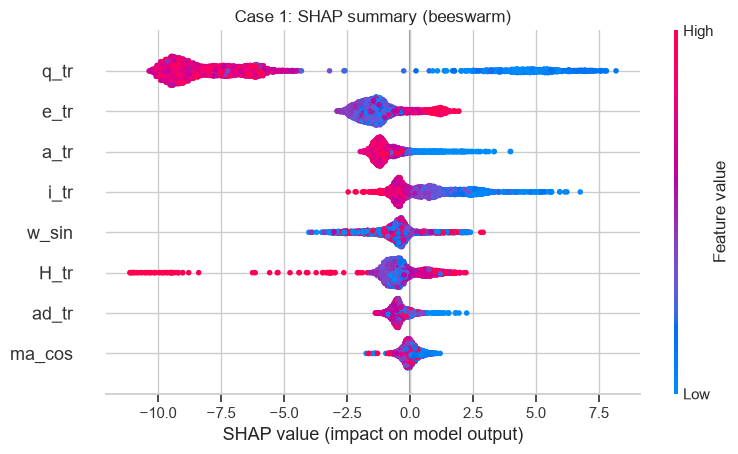

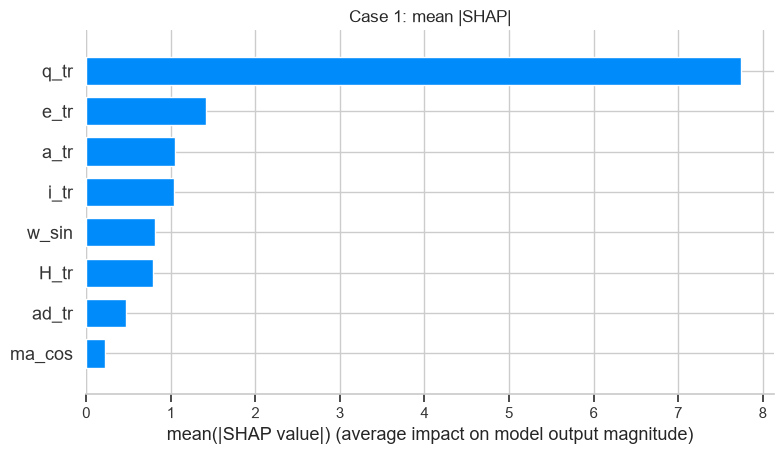

In [3]:
shap.summary_plot(sv1, X1, show=False, max_display=15); plt.title("Case 1: SHAP summary (beeswarm)")
savefig("07_case1_shap_summary")
shap.summary_plot(sv1, X1, plot_type="bar", show=False, max_display=15); plt.title("Case 1: mean |SHAP|")
savefig("07_case1_shap_bar")

**Reading the beeswarm:** each dot is an asteroid; x = push toward (right) or away from (left) "PHA"; colour = feature value. Look for monotone colour gradients (the model learned a simple rule) versus mixed colours (interactions).

### 2.2 Individual predictions: a hit, a false alarm, a miss

In [4]:
y1 = s1["y_pha"].values
i_hit  = int(np.where(y1 == 1)[0][np.argmax(proba1[y1 == 1])])
i_miss = int(np.where(y1 == 1)[0][np.argmin(proba1[y1 == 1])])
i_fp   = int(np.where(y1 == 0)[0][np.argmax(proba1[y1 == 0])])
for tag, i in [("hit (true PHA, most confident)", i_hit), ("false alarm (non-PHA, highest score)", i_fp), ("miss (true PHA, lowest score)", i_miss)]:
    r = s1.iloc[i]; print(f"{tag:42s} {r.full_name:28s} class={r['class']:4s} p={proba1[i]:.3f}  a={r.a:.2f} e={r.e:.2f} i={r.i:.1f} H={r.H:.1f}")

hit (true PHA, most confident)             162120 (1998 SH36)           class=APO  p=1.000  a=1.09 e=0.57 i=2.1 H=20.5
false alarm (non-PHA, highest score)              (2017 KF5)            class=APO  p=0.909  a=1.23 e=0.48 i=27.1 H=22.4
miss (true PHA, lowest score)              468468 (2004 KH17)           class=ATE  p=0.005  a=0.71 e=0.50 i=22.1 H=21.9


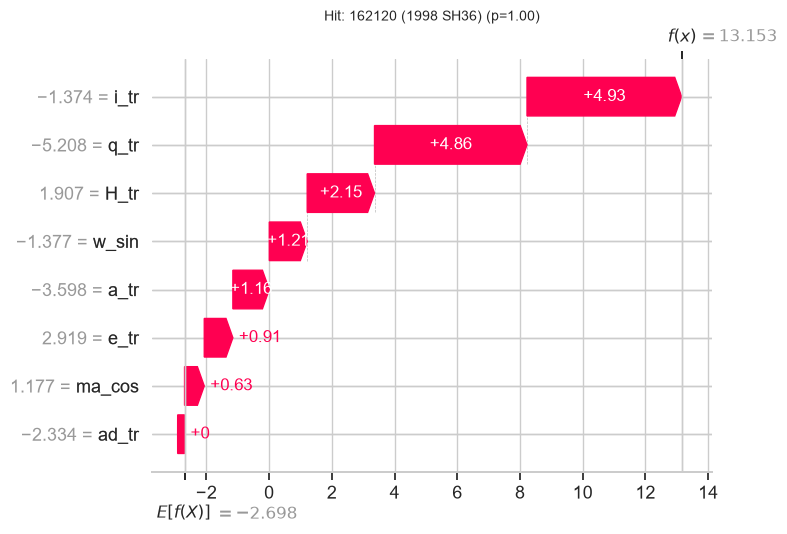

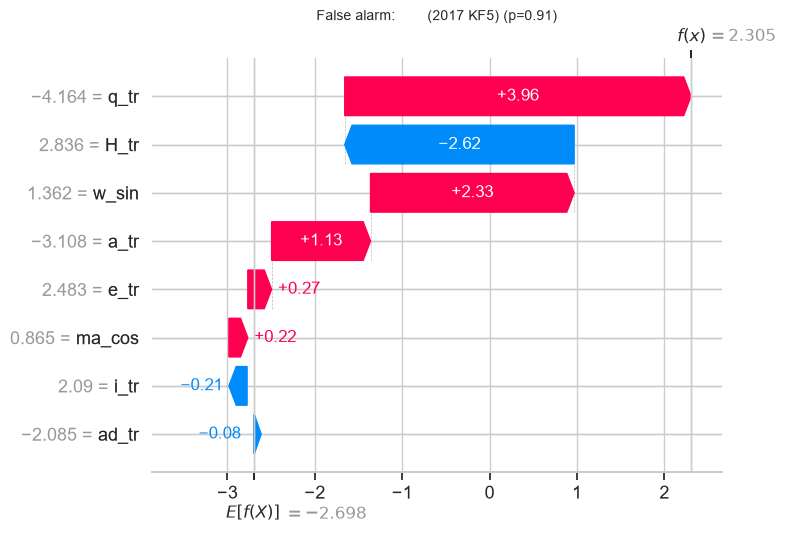

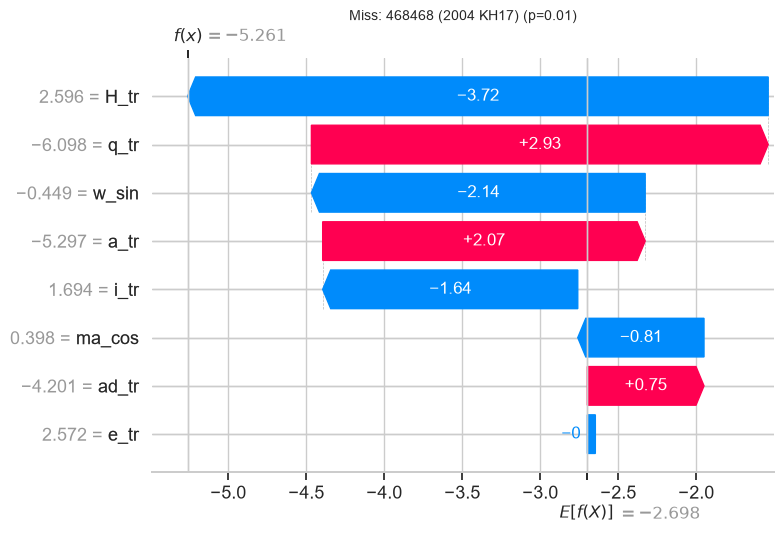

In [5]:
waterfall(sv1, base1, X1, i_hit,  f"Hit: {s1.iloc[i_hit].full_name} (p={proba1[i_hit]:.2f})",  "07_case1_waterfall_hit")
waterfall(sv1, base1, X1, i_fp,   f"False alarm: {s1.iloc[i_fp].full_name} (p={proba1[i_fp]:.2f})", "07_case1_waterfall_false_alarm")
waterfall(sv1, base1, X1, i_miss, f"Miss: {s1.iloc[i_miss].full_name} (p={proba1[i_miss]:.2f})", "07_case1_waterfall_miss")

### 2.3 Dependence: how does the top feature act?

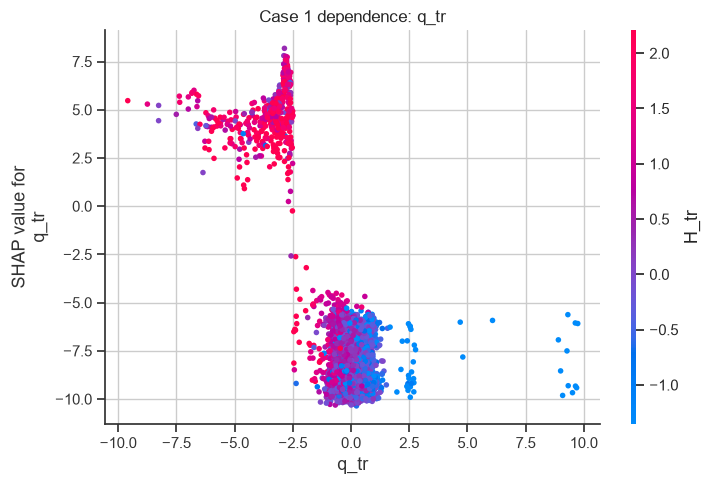

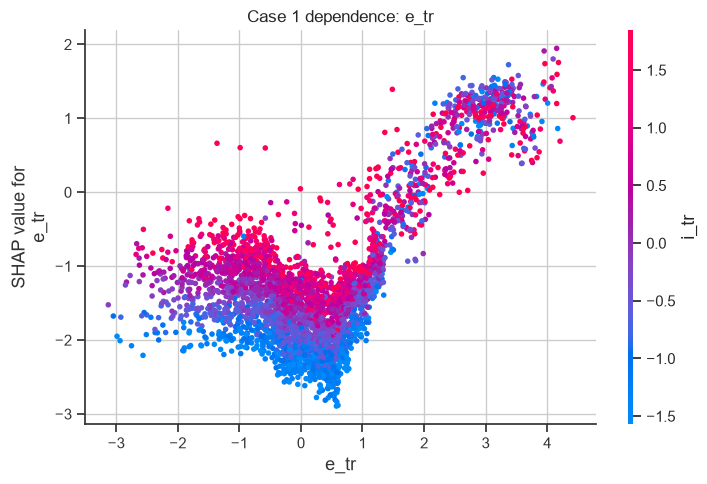

In [6]:
top = pd.Series(np.abs(sv1).mean(0), index=X1.columns).sort_values(ascending=False).index[:2].tolist()
for f in top:
    shap.dependence_plot(f, sv1, X1, show=False); plt.title(f"Case 1 dependence: {f}"); savefig(f"07_case1_dependence_{f}")

### 2.4 SHAP vs the feature selection of notebook 03

In [7]:
rank_file = f"03_feature_rank_case1_{b1['scenario']}.csv"
if not (U.RES / rank_file).exists():
    print(f"(no ranking file for scenario {b1['scenario']}; falling back to B_withH on shared features)")
    rank_file = "03_feature_rank_case1_B_withH.csv"
cmp1, rho1 = rank_vs_selection(sv1, X1, rank_file)
cmp1.to_csv(U.RES / "07_case1_shap_vs_selection.csv")
print(f"Spearman(mean|SHAP|, RF importance from 03) = {rho1:.3f}"); cmp1

Spearman(mean|SHAP|, RF importance from 03) = 0.738


,mean_abs_SHAP,SHAP_rank,RF_importance_03,RF_rank_03,consensus_rank_03
q_tr,7.7463,1.0,0.3998,1.0,1.00
e_tr,1.4191,2.0,0.2575,2.0,3.00
a_tr,1.0471,3.0,0.1223,4.0,3.25
i_tr,1.0342,4.0,0.0110,6.0,6.25
w_sin,0.8139,5.0,0.0008,7.0,9.50
H_tr,0.7906,6.0,0.1563,3.0,3.50
ad_tr,0.4704,7.0,0.0486,5.0,4.50
ma_cos,0.2168,8.0,0.0006,8.0,7.75


## 3. Case 2 — Diameter regressor

In [8]:
b2 = joblib.load(U.MODELS / "case2_diameter_best.joblib")
pipe2, feats2 = b2["pipeline"], b2["features"]
print("model:", b2["scenario"], b2["model"], "| features:", feats2)

df2 = U.read_processed("case2")
t2 = df2[(df2["split"] == "test") & df2["albedo"].notna()].sample(N_REG, random_state=U.SEED).reset_index(drop=True)
pred2 = pipe2.predict(t2[feats2])
est2, X2 = unwrap(pipe2, t2[feats2])
expl2 = get_explainer(est2, X2.sample(min(500, len(X2)), random_state=U.SEED))
sv2 = np.asarray(expl2.shap_values(X2)); base2 = base_value(expl2, classification=False)
print("SHAP matrix:", sv2.shape, "| base value (log10 km):", round(base2, 3), "-> typical diameter", round(10 ** base2, 2), "km")

model: B_withAlbedo RandomForest | features: ['H_tr', 'albedo_tr', 'a_tr', 'q_tr', 'ad_tr', 'i_tr', 'e_tr', 'ma_cos', 'ma_sin']
SHAP matrix: (3000, 9) | base value (log10 km): 0.627 -> typical diameter 4.24 km


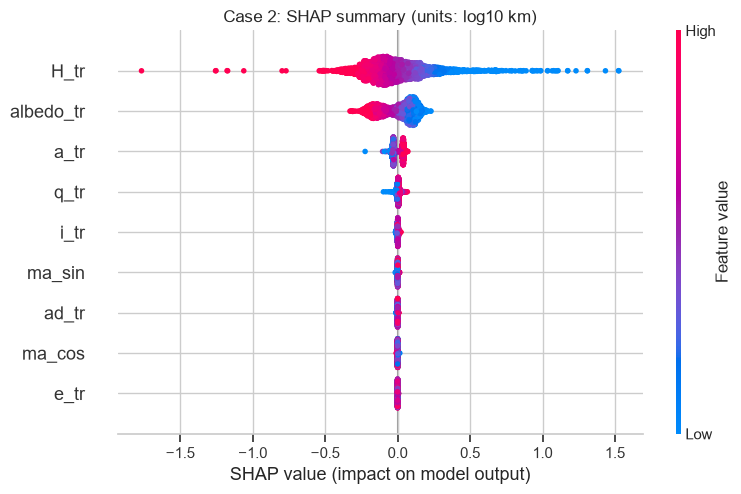

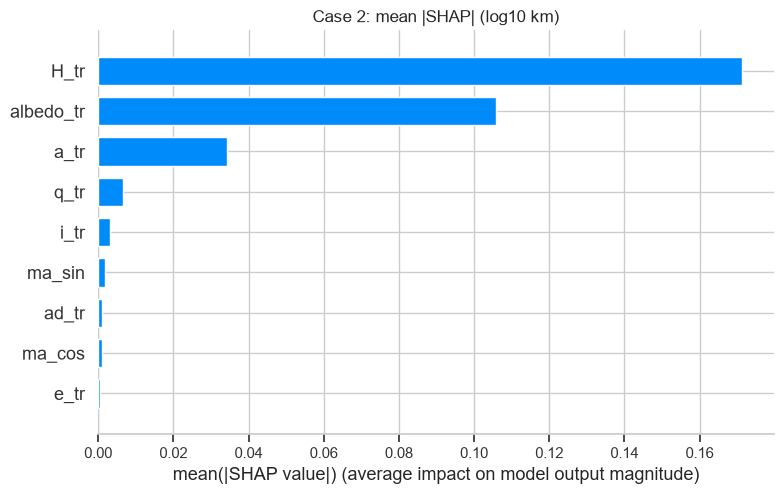

In [9]:
shap.summary_plot(sv2, X2, show=False, max_display=15); plt.title("Case 2: SHAP summary (units: log10 km)")
savefig("07_case2_shap_summary")
shap.summary_plot(sv2, X2, plot_type="bar", show=False, max_display=15); plt.title("Case 2: mean |SHAP| (log10 km)")
savefig("07_case2_shap_bar")

largest          45 Eugenia               class=MBA  true= 202.327 km  pred= 180.622 km  H=7.5 albedo=0.045


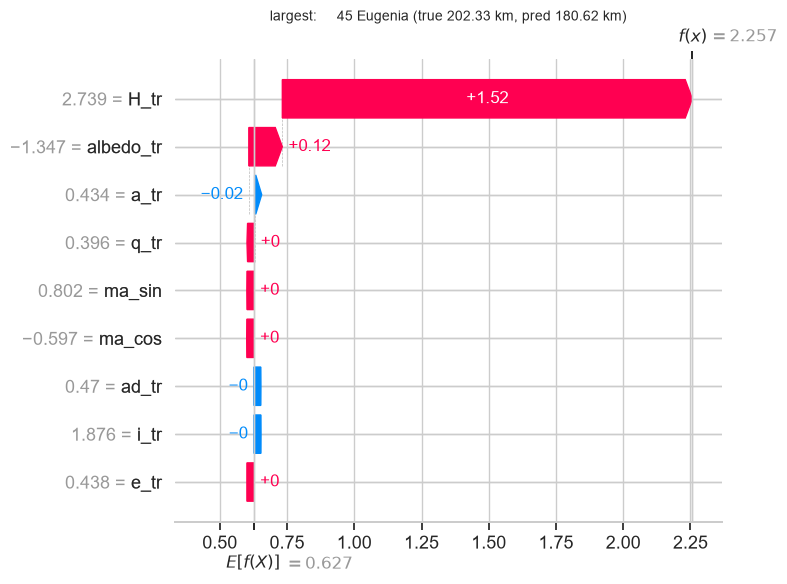

smallest            (2010 GH7)            class=APO  true=   0.008 km  pred=   0.027 km  H=27.3 albedo=0.326


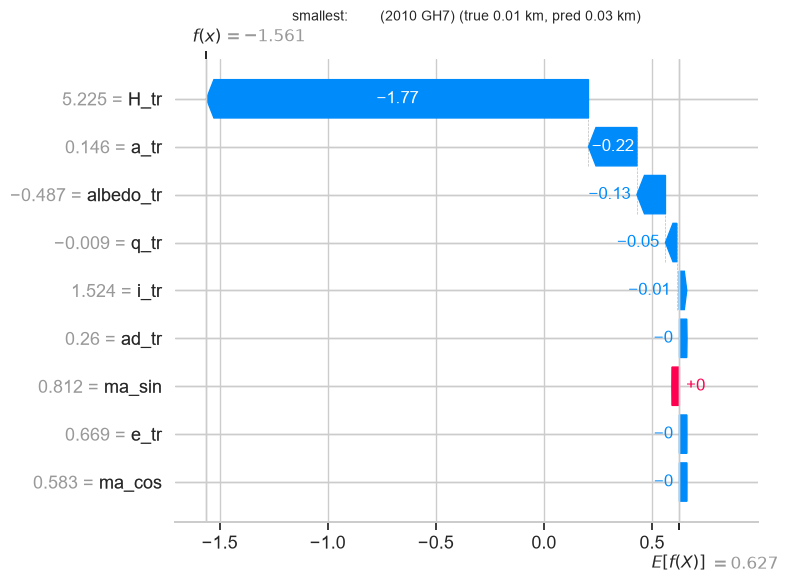

worst error         (2010 GH7)            class=APO  true=   0.008 km  pred=   0.027 km  H=27.3 albedo=0.326


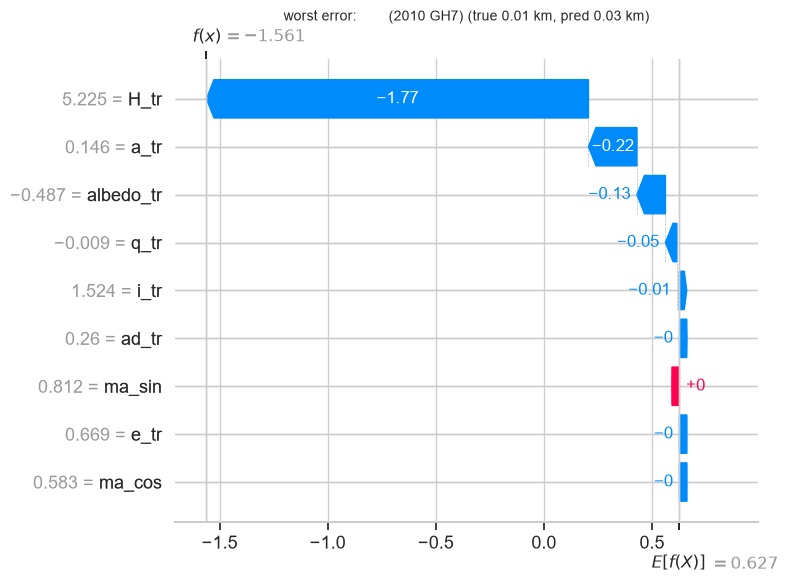

In [10]:
err2 = np.abs(pred2 - t2["log_diameter"].values)
i_big, i_small, i_bad = int(t2["log_diameter"].idxmax()), int(t2["log_diameter"].idxmin()), int(np.argmax(err2))
for tag, i, nm in [("largest", i_big, "big"), ("smallest", i_small, "small"), ("worst error", i_bad, "worst")]:
    r = t2.iloc[i]; print(f"{tag:12s} {r.full_name:28s} class={r['class']:4s} true={r.diameter:8.3f} km  pred={10**pred2[i]:8.3f} km  H={r.H:.1f} albedo={r.albedo:.3f}")
    waterfall(sv2, base2, X2, i, f"{tag}: {r.full_name} (true {r.diameter:.2f} km, pred {10**pred2[i]:.2f} km)", f"07_case2_waterfall_{nm}")

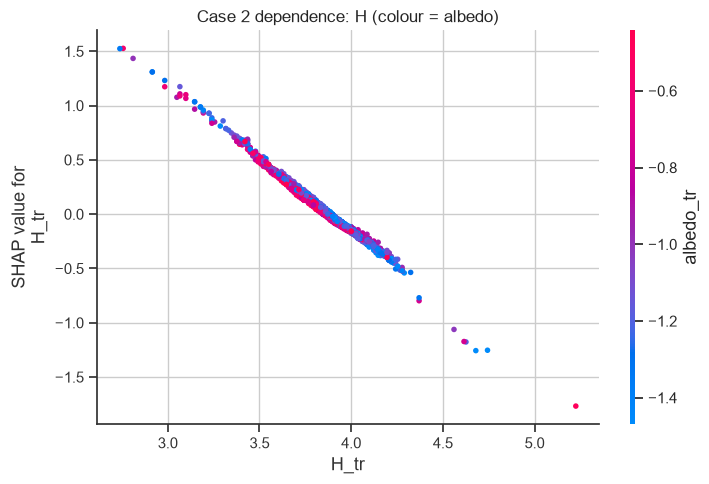

In [11]:
inter = "albedo_tr" if "albedo_tr" in X2.columns else "auto"
shap.dependence_plot("H_tr", sv2, X2, interaction_index=inter, show=False)
plt.title("Case 2 dependence: H (colour = albedo)"); savefig("07_case2_dependence_H")

In [12]:
rank_file2 = f"03_feature_rank_case2_{b2['scenario']}.csv"
cmp2, rho2 = rank_vs_selection(sv2, X2, rank_file2)
cmp2.to_csv(U.RES / "07_case2_shap_vs_selection.csv")
print(f"Spearman(mean|SHAP|, RF importance from 03) = {rho2:.3f}"); cmp2

Spearman(mean|SHAP|, RF importance from 03) = 0.983


,mean_abs_SHAP,SHAP_rank,RF_importance_03,RF_rank_03,consensus_rank_03
H_tr,0.1712,1.0,0.7138,1.0,1.25
albedo_tr,0.1057,2.0,0.1939,2.0,2.50
a_tr,0.0342,3.0,0.0706,3.0,3.00
q_tr,0.0067,4.0,0.0090,4.0,3.50
i_tr,0.0031,5.0,0.0018,5.0,6.00
ma_sin,0.0017,6.0,0.0010,6.0,9.50
ad_tr,0.0011,7.0,0.0010,8.0,5.50
ma_cos,0.0010,8.0,0.0010,7.0,8.75
e_tr,0.0006,9.0,0.0009,9.0,7.75


## 4. Case 3 — cluster inference (for the Streamlit app)

In [13]:
km_b = joblib.load(U.MODELS / "case3_kmeans.joblib"); db_b = joblib.load(U.MODELS / "case3_dbscan.joblib")
nn_core = NearestNeighbors(n_neighbors=1).fit(db_b["core_X"])

def _scaled(a, e, i, bundle):
    raw = pd.DataFrame({"a": [a], "e": [e], "i": [i]})
    return bundle["scaler"].transform(U.transform_features(raw)[bundle["features"]]).astype("float32")

def assign_cluster(a, e, i):
    """K-Means cluster id, plus DBSCAN label via nearest core sample within eps (-1 = noise/outlier)."""
    km_id = int(km_b["kmeans"].predict(_scaled(a, e, i, km_b))[0])
    d, j = nn_core.kneighbors(_scaled(a, e, i, db_b))
    db_id = int(db_b["core_labels"][j[0, 0]]) if d[0, 0] <= db_b["eps"] else -1
    return km_id, db_id

examples = {"Apophis-like (APO)": (0.922, 0.191, 3.3), "Ceres-like (MBA)": (2.77, 0.076, 10.6),
            "Hilda/Trojan-like": (5.2, 0.05, 10.0), "Pluto-like (TNO)": (39.5, 0.25, 17.1)}
out = pd.DataFrame([dict(example=k, a=v[0], e=v[1], i=v[2], **dict(zip(["kmeans_cluster", "dbscan_cluster"], assign_cluster(*v))))
                    for k, v in examples.items()])
out

,example,a,e,i,kmeans_cluster,dbscan_cluster
0,Apophis-like (APO),0.922,0.191,3.3,1,-1
1,Ceres-like (MBA),2.770,0.076,10.6,0,0
2,Hilda/Trojan-like,5.200,0.050,10.0,0,2
3,Pluto-like (TNO),39.500,0.250,17.1,2,-1


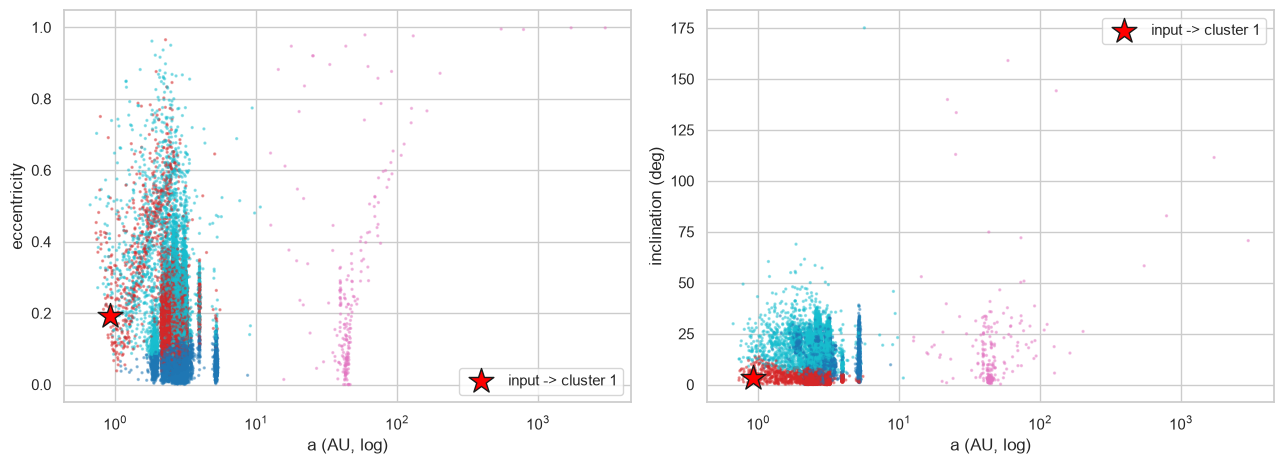

In [14]:
def plot_input(a, e, i, n_bg=60_000):
    """Place one asteroid on the a-e and a-i planes, coloured by K-Means cluster. Reusable by the Streamlit app."""
    bg = U.read_processed("case3", columns=["a", "e", "i", "a_tr", "e_tr", "i_tr"]).sample(n_bg, random_state=U.SEED)
    lab = km_b["kmeans"].predict(km_b["scaler"].transform(bg[km_b["features"]]).astype("float32"))
    cid = assign_cluster(a, e, i)[0]
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
    for ax, (yc, yl) in zip(axes, [("e", "eccentricity"), ("i", "inclination (deg)")]):
        ax.scatter(bg["a"], bg[yc], c=lab, cmap="tab10", s=2, alpha=0.4)
        ax.scatter([a], [{"e": e, "i": i}[yc]], marker="*", s=350, c="red", edgecolor="k", zorder=5, label=f"input -> cluster {cid}")
        ax.set_xscale("log"); ax.set_xlabel("a (AU, log)"); ax.set_ylabel(yl); ax.legend()
    return fig

plot_input(0.922, 0.191, 3.3); savefig("07_case3_input_placement_example")